<a href="https://colab.research.google.com/github/rzjuliannofficial/PCVK_18_Julian/blob/main/PCVK_W9_2341720255_Nabhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 – Praktikum Morfologi Citra
**Pengolahan Citra dan Visi Komputer** – Erosi, Dilasi, Opening, Closing, Top-hat, Black-hat, Skeleton, Thinning


## Percobaan 1 – Menyiapkan Google Colab


In [1]:
from google.colab import drive
drive.mount('/content/drive')

PATH = '/content/drive/MyDrive/Kuliah/Semester5/PCVK/Img'   # sesuaikan dengan folder gambar kamu

Mounted at /content/drive


**Kesimpulan**
Setelah *mount* berhasil, isi Drive bisa diakses lewat `/content/drive`. Semua gambar dibaca lewat `PATH`, jadi jika folder pindah cukup mengubah satu baris.

## Percobaan 2 – Import Library
**Penjelasan**
- `cv2` untuk membaca citra dan operasi morfologi, `numpy` untuk array, `matplotlib` untuk menampilkan citra.
- `daftar_file` berisi dua gambar yang akan diulang pada percobaan plat/noisy_text.

**Pengerjaan**

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

daftar_file = ['plat nomer_hitam.jpg', 'noisy_text.png']   # dua gambar untuk perulangan

**Kesimpulan**
Library siap dipakai. Library untuk skeleton dan thinning (`scikit-image`) diimpor pada Percobaan 15–17 sesuai modul.

## Percobaan 3 – Dilasi TANPA Library (SED persegi, `w=5`)
**Penjelasan**
- **Dilasi** membuat objek putih **membesar/menebal**: piksel hasil = 1 jika setidaknya ada satu piksel di area *Structuring Element* yang bernilai 1 (`np.max`).
- Kode modul membuat SED `np.ones((w,w))` dan dipakai dengan `w=5`, jadi SED yang benar-benar dipakai adalah persegi 5x5.

**Pengerjaan**

In [3]:
#Dilasi tanpa library

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

Citra: plat nomer_hitam.jpg


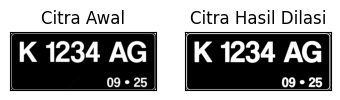

Citra: noisy_text.png


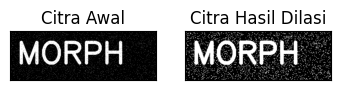

In [31]:
#SED 3x3
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=3 #3X3
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

Citra: plat nomer_hitam.jpg


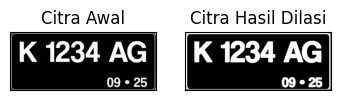

Citra: noisy_text.png


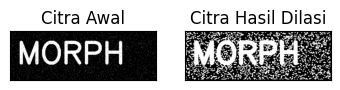

In [32]:
#SED 5x5
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=5 #5X5
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- **Plat:** huruf, angka, garis tepi, dan tulisan kecil `09 • 25` menjadi **lebih tebal**.
- **noisy_text:** huruf ikut menebal, tetapi **bintik noise putih di latar membesar dan menyebar padat** sehingga latar penuh bercak putih. Dilasi tidak membedakan objek dan noise: semua yang putih ikut membesar.
- SED yang dipakai kode modul adalah persegi 3x3 (`np.ones((w,w))` dengan `w=3`) dan 5x5 (`np.ones((w,w))` dengan `w=5`).

## Percobaan 4 – Dilasi DENGAN Library
**Penjelasan**
Memakai `cv2.dilate()` dengan kernel `np.ones((3,3))` seperti kode modul (kernel persegi 3x3). Gambar dibaca berwarna lalu dikonversi ke grayscale dengan `cv2.cvtColor` (cara yang sama dipakai modul pada percobaan 13).

**Pengerjaan**

Citra: plat nomer_hitam.jpg
[[1 1 1]
 [1 1 1]
 [1 1 1]]


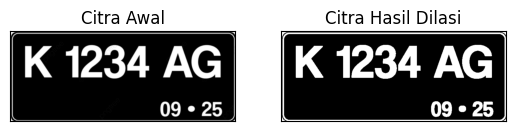

Citra: noisy_text.png
[[1 1 1]
 [1 1 1]
 [1 1 1]]


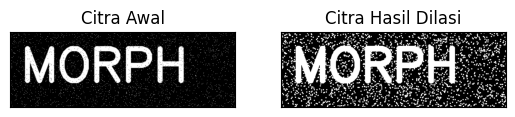

In [5]:
for nama in daftar_file:
    print('Citra:', nama)

    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # diperbaiki: konversi ke grayscale

    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint16) #3X3
    dilasi = cv2.dilate(thresh,kernel,iterations = 1)
    print(kernel)

    plt.subplot(121),plt.imshow(img,cmap = 'gray'),plt.title('Citra Awal')   # diperbaiki: cmap gray
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(dilasi,cmap = 'gray'),plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Prinsipnya sama dengan Percobaan 3, tetapi dengan `cv2.dilate` cukup satu baris tanpa loop manual.
- Kernel yang dipakai persegi 3x3 (lebih kecil dari 5x5 pada Percobaan 3), sehingga penebalannya **lebih kecil**: huruf plat menebal tipis dan bintik noise pada noisy_text membesar tetapi tidak sepadat pada Percobaan 3.
- Semakin besar SE, semakin besar penebalan, baik pada objek maupun pada noise.

## Percobaan 5 – Erosi Square 5x5 TANPA Library
**Penjelasan**
- **Erosi** membuat objek putih **mengecil/menipis**: piksel hasil = 1 hanya jika **semua** piksel di area SE bernilai 1 (`np.min`).
- SE square 5x5 berisi 25 angka 1, sehingga goresan putih yang lebarnya kurang dari 5 piksel terkikis.

**Pengerjaan**

In [6]:
#Erosi Tanpa Library

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

Citra: plat nomer_hitam.jpg


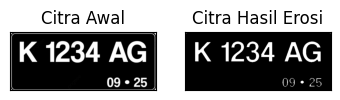

Citra: noisy_text.png


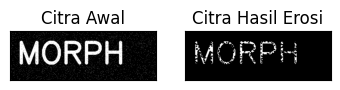

In [7]:
for nama in daftar_file:
    print('Citra:', nama)

    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)

    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- **Plat:** huruf **menipis**; garis tepi dan tulisan kecil `09 • 25` menjadi sangat tipis dan redup karena goresannya hanya beberapa piksel.
- **noisy_text:** **bintik noise putih di latar hilang seluruhnya** karena lebih kecil dari SE 5x5. Namun huruf ikut menipis dan menjadi **berbintik/berlubang**, sebab bintik hitam di dalam huruf melebar saat erosi.
- Erosi efektif untuk membuang noise putih kecil, tetapi objek utama ikut terkikis.

## Percobaan 6 – Erosi Square 5x5 DENGAN Library
**Penjelasan**
Memakai `cv2.erode()` dengan kernel `np.ones((5,5))`. Pada kode modul, erosi dilakukan langsung pada gambar (tanpa *threshold*). Judul soal modul tertulis "dilasi", yang dimaksud adalah **erosi**.

**Pengerjaan**

Citra: plat nomer_hitam.jpg


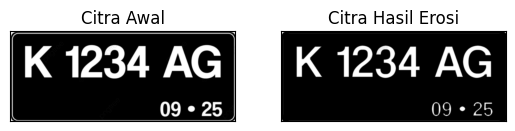

Citra: noisy_text.png


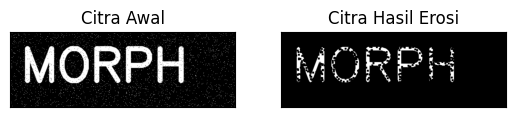

In [8]:
#EROSI LIBRARY
for nama in daftar_file:
    print('Citra:', nama)

    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # diperbaiki: konversi ke grayscale

    kernel = np.ones((5,5),np.uint8)
    erosion = cv2.erode(img,kernel,iterations = 1)
    plt.subplot(121),plt.imshow(img,cmap = 'gray'),plt.title('Citra Awal')   # diperbaiki: cmap gray
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(erosion,cmap = 'gray'),plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Hasil `cv2.erode` **mirip** dengan erosi manual pada Percobaan 5: huruf menipis, tulisan kecil redup, dan noise di latar hilang. Pada noisy_text, huruf tetap tampak berlubang-lubang.
- Perbedaan kecil muncul karena modul mengerosi gambar grayscale langsung (tanpa *threshold*), sedangkan Percobaan 5 mengerosi citra biner.
- Library cukup satu baris dan lebih ringkas dibanding loop manual, dengan efek yang sama: **objek mengecil**.

## Percobaan 7 – Opening (Tanpa dan Dengan Library)
**Penjelasan**
- **Opening = erosi lalu dilasi**: `A ∘ B = (A ⊖ B) ⊕ B`. Fungsinya menghapus objek/noise putih kecil tanpa mengubah objek besar secara berarti.
- Opening bersifat idempotent (diulang tidak mengubah hasil lagi).
- Kode modul: tanpa library memakai `k=7`, dengan library memakai kernel 3x3.

**Pengerjaan – tanpa library**

Citra: plat nomer_hitam.jpg


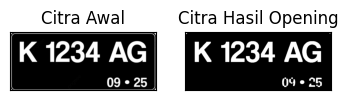

Citra: noisy_text.png


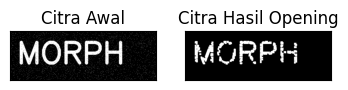

In [9]:
for nama in daftar_file:
    print('Citra:', nama)

    img_o= cv2.imread(f'{PATH}/{nama}',0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgO = dilasi_citra(erosi_citra(thresho,k),k)

    plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

**Pengerjaan – dengan library**

Citra: plat nomer_hitam.jpg


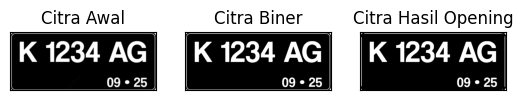

Citra: noisy_text.png


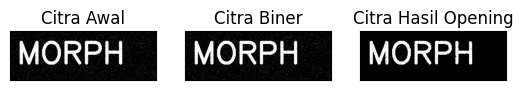

In [10]:
#Dengan Menggunakan Library
for nama in daftar_file:
    print('Citra:', nama)

    img = cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(openn,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

    plt.show()

**Kesimpulan / Analisis**
- **Tanpa library (k=7):** pada plat, huruf besar bertahan tetapi bagian yang lebih tipis dari SE (tulisan kecil `09 • 25` dan garis tepi) **rusak/hilang**. Pada noisy_text, noise di latar hilang, huruf masih terbaca tetapi **tepinya kasar dan berlubang**.
- **Dengan library (k=3):** plat hampir sama dengan citra biner, dan pada noisy_text **noise latar hilang** sementara huruf tetap utuh. SE kecil membuang noise dengan merusak objek sesedikit mungkin.
- Opening hanya membuang bagian putih yang kecil; **lubang hitam di dalam huruf tidak ditutup**. SE harus lebih kecil dari objek yang ingin dipertahankan.

## Percobaan 8 – Closing (Tanpa dan Dengan Library)
**Penjelasan**
- **Closing = dilasi lalu erosi**: `A • B = (A ⊕ B) ⊖ B`. Fungsinya menutup lubang kecil di dalam objek dan menyambung bagian yang hampir terputus.
- Kode modul: tanpa library memakai `k=7`, dengan library memakai kernel 3x3.

**Pengerjaan – tanpa library**

Citra: plat nomer_hitam.jpg


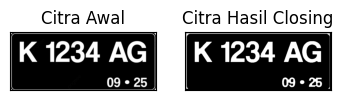

Citra: noisy_text.png


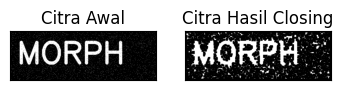

In [11]:
for nama in daftar_file:
    print('Citra:', nama)

    img_c= cv2.imread(f'{PATH}/{nama}',0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgC = erosi_citra(dilasi_citra(threshc,k),k)

    plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

**Pengerjaan – dengan library**

Citra: plat nomer_hitam.jpg


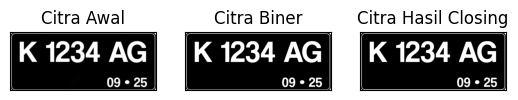

Citra: noisy_text.png


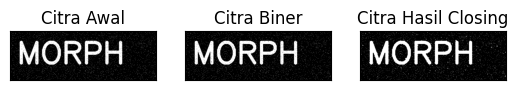

In [12]:
for nama in daftar_file:
    print('Citra:', nama)

    img = cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(closs,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

    plt.show()

**Kesimpulan / Analisis**
- **Tanpa library (k=7):** pada plat, bentuk huruf dan tulisan kecil hampir tidak berubah (celah kecil tertutup). Pada noisy_text, **bintik noise menyatu dengan huruf** dan membentuk bercak tidak beraturan di sekitar huruf.
- **Dengan library (k=3):** plat hampir tidak berubah. Pada noisy_text, **noise putih di latar tidak hilang** (huruf tampak lebih solid karena lubang kecilnya tertutup).
- Closing menutup **lubang/celah gelap**, bukan membuang noise putih (itu fungsi opening). SE besar pada citra ber-noise justru menyatukan noise.

## Percobaan 9 – Dilasi dengan SED Cross 3x3 dan 5x5
**Penjelasan**
- SED cross berisi satu baris dan satu kolom tengah bernilai 1 (bentuk tanda tambah).
- Cross 3x3 menebalkan objek 1 piksel, cross 5x5 menebalkan 2 piksel ke arah atas, bawah, kiri, kanan.
- Fungsi `dilasi_citra` didefinisikan ulang (seperti di modul) dengan SED berbentuk cross.

**Pengerjaan – Cross 3**

In [13]:
#Dilasi Cross SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 3
Citra: plat nomer_hitam.jpg


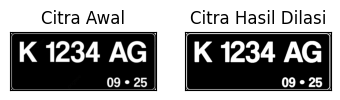

Citra: noisy_text.png


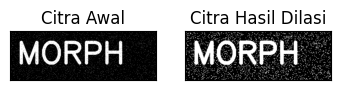

In [14]:
print('SED = Cross 3')
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Pengerjaan – Cross 5**

In [15]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Cross 5
Citra: plat nomer_hitam.jpg


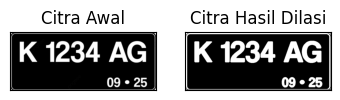

Citra: noisy_text.png


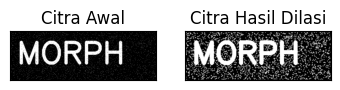

In [16]:
print('SED = Cross 5')
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Cross 3 menebalkan objek 1 piksel dan cross 5 menebalkan 2 piksel ke arah atas, bawah, kiri, kanan. Pada plat, huruf lebih tebal pada cross 5 tetapi masih terpisah.
- Pada noisy_text, bintik noise **membesar mengikuti ukuran SE** dan latar makin ramai. Sebaiknya noise dibersihkan dulu (misalnya dengan opening) sebelum dilasi.

## Percobaan 10 – Dilasi dengan SED Circular 3x3 dan 5x5
**Penjelasan**
SED circular (elips/lingkaran) dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w,w))`. Pada ukuran kecil, bentuk lingkaran harus dibulatkan ke piksel sehingga tampak mirip cross.

**Pengerjaan**

In [17]:
#Dilasi Circular SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

SED = Circle 3
Citra: plat nomer_hitam.jpg


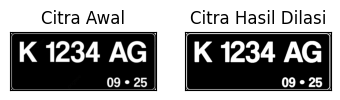

Citra: noisy_text.png


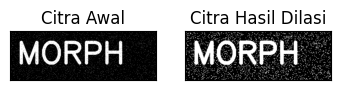

In [18]:
print('SED = Circle 3')
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

SED = Circle 5
Citra: plat nomer_hitam.jpg


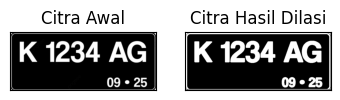

Citra: noisy_text.png


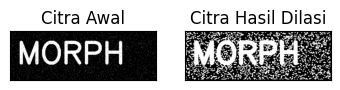

In [19]:
print('SED = Circle 5')
for nama in daftar_file:
    print('Citra:', nama)

    img_d= cv2.imread(f'{PATH}/{nama}',0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Pada ukuran 3x3, SE circular berbentuk sama dengan cross 3x3, sehingga hasil dilasinya setara dengan Cross 3 pada Percobaan 9.
- Pada 5x5, SE circular lebih "gemuk" dari cross 5 (bagian sudutnya ikut terisi), sehingga penebalan lebih merata dan lebih besar. Pada noisy_text, latar menjadi lebih penuh bercak dibanding Cross 5.
- Circular cocok jika ingin penebalan yang seragam ke segala arah.

## Percobaan 11 – Erosi dengan SE Rectangle 3x5 dan 5x7
**Penjelasan**
- SE persegi panjang dibuat dengan `cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))` dengan `p` = lebar (kolom) dan `l` = tinggi (baris). Jadi `p=5, l=3` adalah SE 3 baris x 5 kolom.
- Erosi memperkecil objek sebesar (ukuran SE − 1) pada tiap arah.

**Pengerjaan**

In [20]:
#Erosi Rectangle SE

def erosi_citra(F,p,l):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

SE = Rectangle 3x5
Citra: plat nomer_hitam.jpg


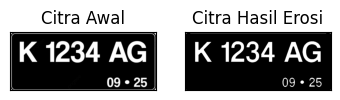

Citra: noisy_text.png


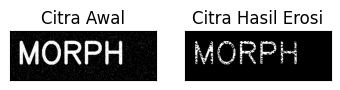

In [21]:
print('SE = Rectangle 3x5')
for nama in daftar_file:
    print('Citra:', nama)

    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=5
    l=3
    imgE = erosi_citra(thresh1,p,l)

    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

SE = Rectangle 5x7
Citra: plat nomer_hitam.jpg


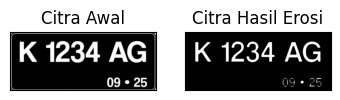

Citra: noisy_text.png


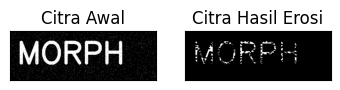

In [22]:
print('SE = Rectangle 5x7')
for nama in daftar_file:
    print('Citra:', nama)

    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    p=7
    l=5
    imgE = erosi_citra(thresh1,p,l)

    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- **noisy_text:** noise di latar **hilang total**, tetapi huruf menjadi tipis dan berlubang-lubang.
- **Plat:** huruf menipis, dan tulisan kecil `09 • 25` hampir hilang pada 5x7.
- SE 5x7 mengikis lebih banyak daripada 3x5. Erosi memperkecil objek sebesar (ukuran SE − 1) pada tiap arah, jadi karena SE lebih lebar daripada tinggi, objek menyusut lebih banyak ke arah mendatar (4 piksel pada 3x5 dan 6 piksel pada 5x7) daripada ke arah tegak (2 dan 4 piksel).

## Percobaan 12 – Erosi dengan SE Line Vertikal 3 dan 5
**Penjelasan**
- SE line vertikal dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1,k))`, yaitu matriks k baris x 1 kolom berisi angka 1.
- Modul menyebut gambar `j.png`, tetapi kode modul memakai gambar plat. Di sini dipakai plat dan noisy_text (perulangan).
- Catatan: jendela `temp` pada kode modul berukuran k x k, bukan k x 1.

**Pengerjaan**

In [23]:
#Erosi Line Vertikal SE

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

SE = Line Vertikal 3
Citra: plat nomer_hitam.jpg


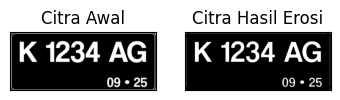

Citra: noisy_text.png


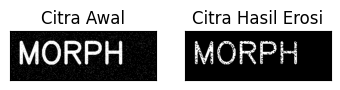

In [24]:
print('SE = Line Vertikal 3')
for nama in daftar_file:
    print('Citra:', nama)

    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=3
    imgE = erosi_citra(thresh1,k)

    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

SE = Line Vertikal 5
Citra: plat nomer_hitam.jpg


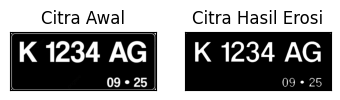

Citra: noisy_text.png


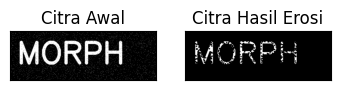

In [25]:
print('SE = Line Vertikal 5')
for nama in daftar_file:
    print('Citra:', nama)

    img_e= cv2.imread(f'{PATH}/{nama}',0)
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)

    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Hasilnya mirip erosi persegi: huruf menipis, tulisan kecil makin redup, dan **noise di latar hilang**. Line 5 mengikis lebih banyak daripada line 3.
- Alasannya, SE-nya memang k x 1 (line vertikal), tetapi jendela `temp` pada kode modul berukuran k x k. Perkalian `temp*SE` lalu diperluas ke seluruh jendela, sehingga `np.min` melihat area persegi k x k. Agar benar-benar mengikis secara vertikal saja, jendelanya harus k x 1.

## Percobaan 13 – Transformasi Top-hat (SE 3x3)
**Penjelasan**
- **Top-hat = citra asli − opening**: `T(f) = f − (f ∘ B)`.
- Hasilnya hanya menyisakan **fitur terang yang lebih kecil dari SE**, berguna untuk meratakan pencahayaan latar yang tidak merata sebelum *thresholding*.
- Kode modul membaca gambar plat (lalu `cvtColor` ke grayscale), sedangkan contoh hasil di modul menampilkan gambar kucing. Karena itu perulangan memakai dua gambar plat/noisy_text sesuai kode, ditambah `kitten01.jpg` sesuai contoh hasil modul.

**Pengerjaan**

Citra: plat nomer_hitam.jpg


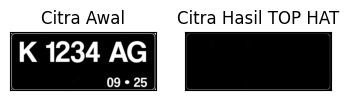

Citra: noisy_text.png


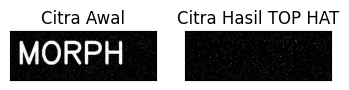

Citra: kitten01.jpg


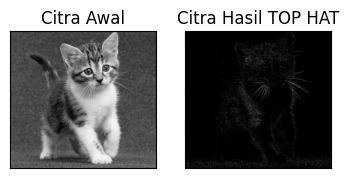

In [26]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                                   filterSize)

for nama in daftar_file + ['kitten01.jpg']:
    print('Citra:', nama)

    # Reading the image
    img = cv2.imread(f'{PATH}/{nama}')
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Applying the Top-Hat operation
    tophat_img = cv2.morphologyEx(img,    # diperbaiki: modul memakai input_image yang belum didefinisikan
                                  cv2.MORPH_TOPHAT,
                                  kernel)

    #cv2.imshow("original", input_image)
    #cv2.imshow("tophat", tophat_img)
    #cv2.waitKey(5000)
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
    plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
    plt.show()

**Kesimpulan / Analisis**
- Top-hat = citra asli − opening. Hasilnya hanya fitur terang yang lebih kecil dari SE 3x3.
- **Plat:** hasil **hampir hitam**, karena huruf jauh lebih besar dari SE sehingga tidak ada fitur terang sekecil itu.
- **noisy_text:** yang muncul samar adalah **bintik noise putih** (fitur terang kecil), sedangkan huruf tidak muncul.
- **Kucing:** hasil gelap dan hanya detail halus yang terang, seperti kumis dan ujung bulu, sesuai contoh pada modul.

## Percobaan 14 – Transformasi Black-hat
**Penjelasan**
- **Black-hat = citra hasil closing dikurangi citra asli**: `B(f) = (f • B) − f`. Arah pengurangan penting: closing selalu ≥ citra asli, sehingga jika dibalik hasilnya nol.
- Hasilnya menyisakan **fitur gelap yang lebih kecil dari SE**.
- Kode modul membuat `kernel` 3x3, tetapi yang dipakai pada `morphologyEx` adalah `Kernel` 13x5 (baris 3x3 yang memakai `kernel` sudah dijadikan komentar di modul). Gambar yang dipakai `kitten01.jpg`.

**Pengerjaan**

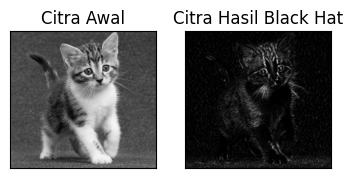

In [27]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread(f'{PATH}/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

**Kesimpulan / Analisis**
- Black-hat = closing − citra asli, menyisakan fitur **gelap** yang lebih kecil dari SE. Hasil pada kucing: mata, hidung, celah gelap di antara bulu, dan garis belang tipis tampak terang, sedangkan area lebar yang rata menjadi hitam.
- Ini kebalikan top-hat yang mengambil fitur terang kecil.
- Kode modul memakai `Kernel` 13x5 pada `morphologyEx`, bukan kernel 3x3. Kernel yang lebih besar menangkap struktur gelap yang lebih besar.

## Percobaan 15 – Skeleton pada Citra Biner (`lily.jpg`)
**Penjelasan**
- **Skeleton** adalah rangka objek setipis 1 piksel yang tetap menjaga bentuk dan topologi objek.
- Citra dibinerkan dengan *threshold triangle*: `binary = img > threshold_triangle(img)`, lalu `skeletonize`.

**Pengerjaan**

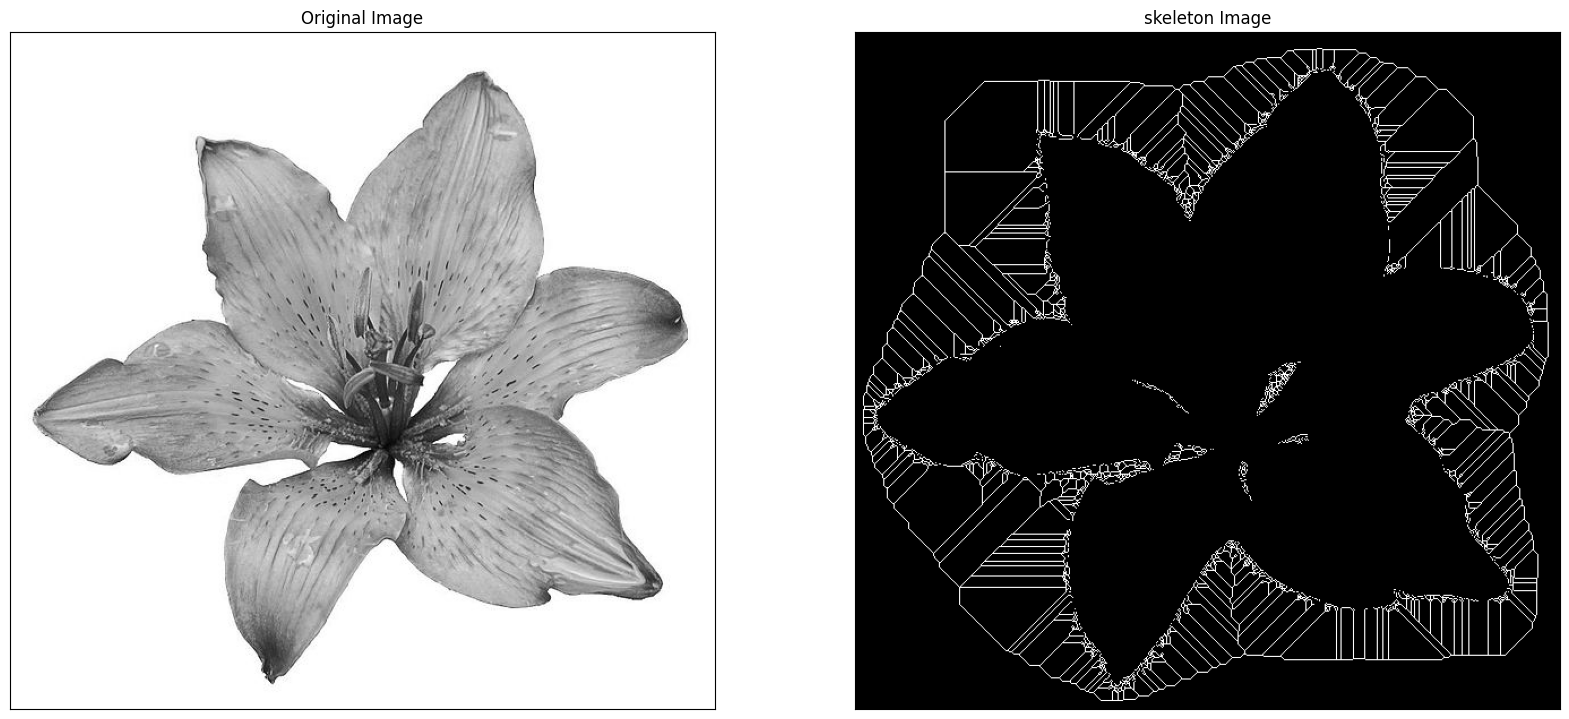

In [28]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread(f'{PATH}/lily.jpg',0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

**Kesimpulan / Analisis**
- Bunga lily berlatar **putih**. Latar putih lebih terang dari ambang sehingga yang bernilai `True` adalah **latar**, bukan bunga.
- Akibatnya skeleton yang terbentuk adalah rangka dari **latar putih**: garis-garis mengelilingi bunga, sedangkan area bunga kosong. Algoritmanya benar, tetapi objek yang dirangkakan bukan bunga.
- Skeleton sangat bergantung pada binerisasi: objek yang ingin dirangkakan harus bernilai True.

## Percobaan 16 – Skeleton pada Citra Hasil Inversi (`lily.jpg`)
**Penjelasan**
- Binerisasi dibalik: `binary = img < threshold_triangle(img)`, sehingga bagian **gelap** menjadi True (objek).
- Hasil ditampilkan dengan `gray_r` (peta warna terbalik), lalu dibandingkan dengan Percobaan 15.

**Pengerjaan**

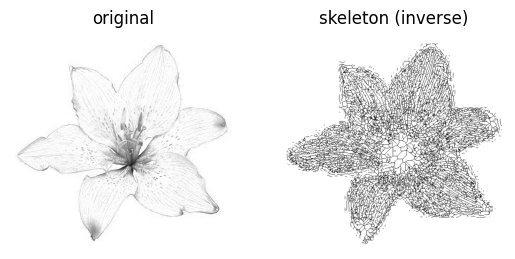

In [29]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread(f'{PATH}/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

**Kesimpulan / Analisis (perbandingan dengan Percobaan 15)**
| | Percobaan 15 | Percobaan 16 |
|---|---|---|
| Tanda binerisasi | `img > ambang` | `img < ambang` |
| Yang bernilai True | Latar putih | Bagian gelap (bunga) |
| Rangka yang terbentuk | Garis di sekeliling bunga | Jaring garis di dalam bunga |

- Setelah inversi, skeleton mewakili **bunga**: jaring garis mengikuti bentuk kelopak, urat, dan bintik gelap.
- Rangkanya tampak ramai dan bercabang banyak karena tekstur gelap kelopak ikut menjadi objek.

## Percobaan 17 – Thinning dengan `morphology.thin()` (`lily.jpg`)
**Penjelasan**
- **Thinning** menipiskan objek berulang kali sampai setipis 1 piksel dengan operasi hit-or-miss (`A ⊗ B = A − (A ⊛ B)`).
- Hasilnya dibandingkan dengan skeleton (`skeletonize`) pada citra yang sama.

**Pengerjaan**

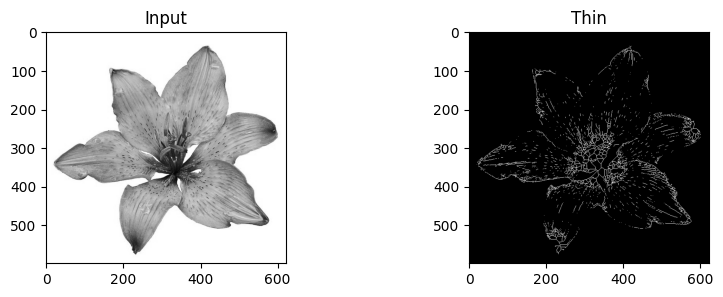

In [30]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread(f'{PATH}/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

**Kesimpulan / Analisis (perbandingan dengan skeleton langkah 15)**
- `thin` menghasilkan garis setebal **1 piksel**, sama seperti skeleton, tetapi hanya pada bagian bunga yang cukup gelap (`image < 0.5`): urat, bintik, dan bagian kelopak yang gelap.
- Skeleton langkah 15 merangkai **latar putih** (garis mengelilingi bunga), sedangkan `thin` di sini bekerja pada **bagian gelap bunga**. Bedanya terutama karena objek yang dibinerkan berbeda, bukan hanya karena algoritmanya.
- Thinning dan skeletonize sama-sama menipiskan objek menjadi rangka; hasil akhirnya sangat ditentukan oleh binerisasi.